In [8]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

In [3]:
rng = np.random.default_rng(0)
states = ["CA", "NY", "TX", "IL", "PA", "OH"]
pop = dict(zip(states, [10, 9, 7, 6, 5, 4]))
rows = []
for y in range(1955, 1985):
    vax = 0.08 if y >= 1970 else 1.0                      # vaccine effect
    for w in range(1, 53):
        season = 1 + 0.8 * np.sin(2 * np.pi * (w - 10) / 52)   # spring peak
        for st in states:
            rows.append((y, w, st, rng.poisson(pop[st] * 6 * season * vax)))
df = pd.DataFrame(rows, columns=["year", "week", "state", "cases"])
print("[info] no CSV given -> using SYNTHETIC data\n")

[info] no CSV given -> using SYNTHETIC data



In [4]:
yearly = df.groupby("year")["cases"].sum()
by_state = df.groupby("state")["cases"].sum().sort_values(ascending=False)
by_week = df.groupby("week")["cases"].mean()
print("Top 5 years by total cases:\n", yearly.sort_values(ascending=False).head(5), "\n")
print("Total cases by state:\n", by_state, "\n")
print("Peak week of year (mean weekly cases):", int(by_week.idxmax()))

Top 5 years by total cases:
 year
1967    13000
1958    12993
1969    12967
1964    12951
1960    12828
Name: cases, dtype: int64 

Total cases by state:
 state
CA    50638
NY    45350
TX    35392
IL    30410
PA    25257
OH    20358
Name: cases, dtype: int64 

Peak week of year (mean weekly cases): 24


In [10]:
%matplotlib inline

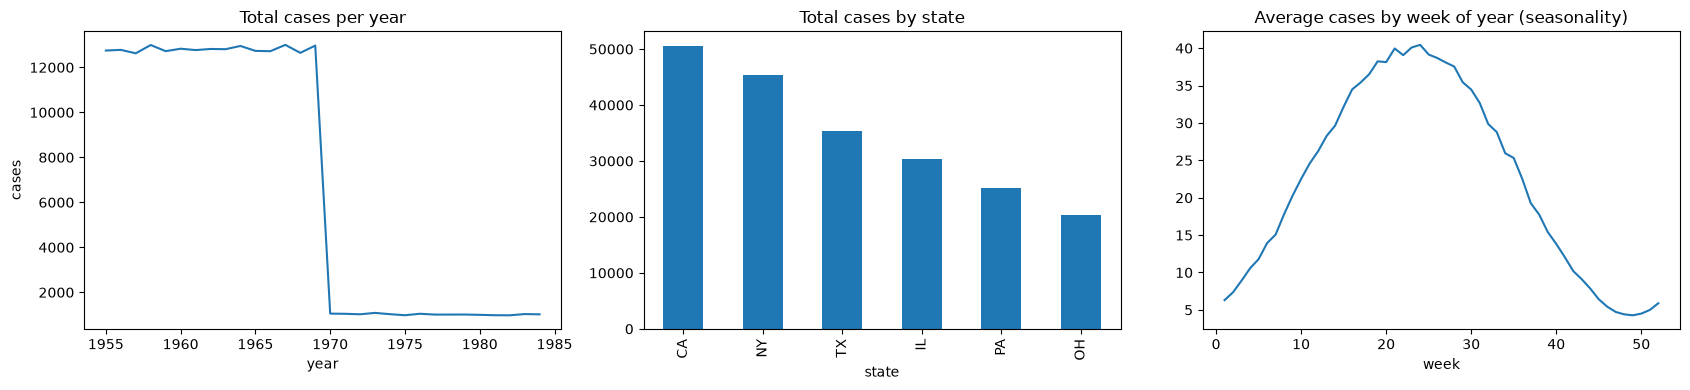

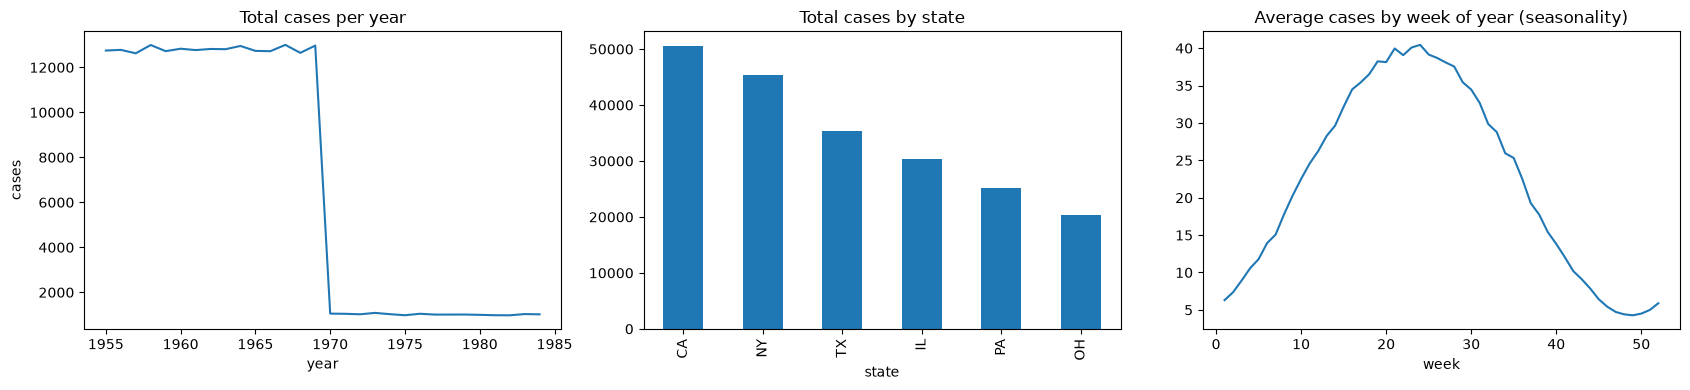

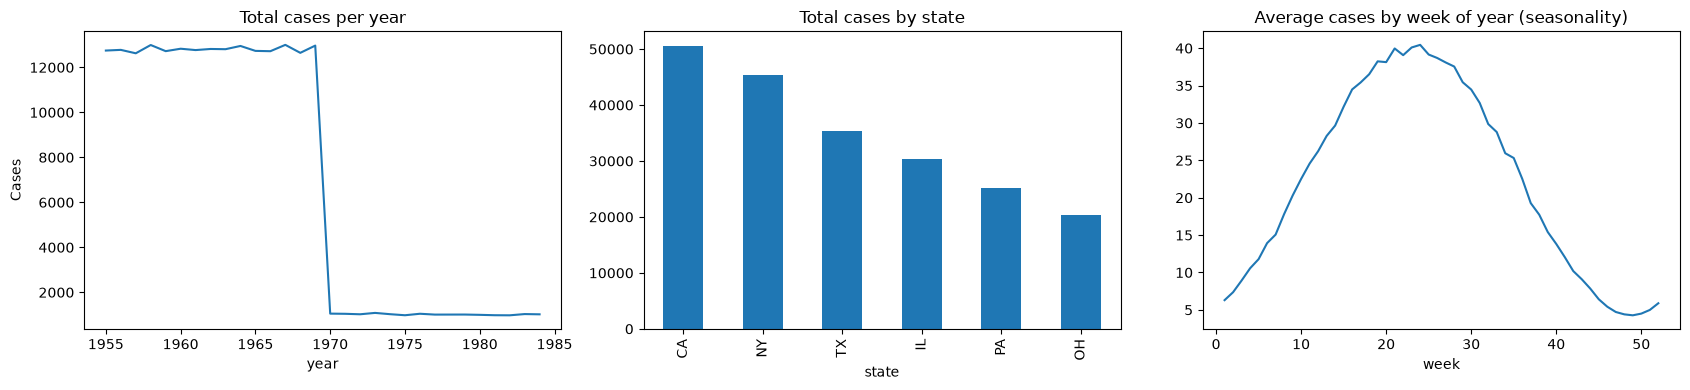

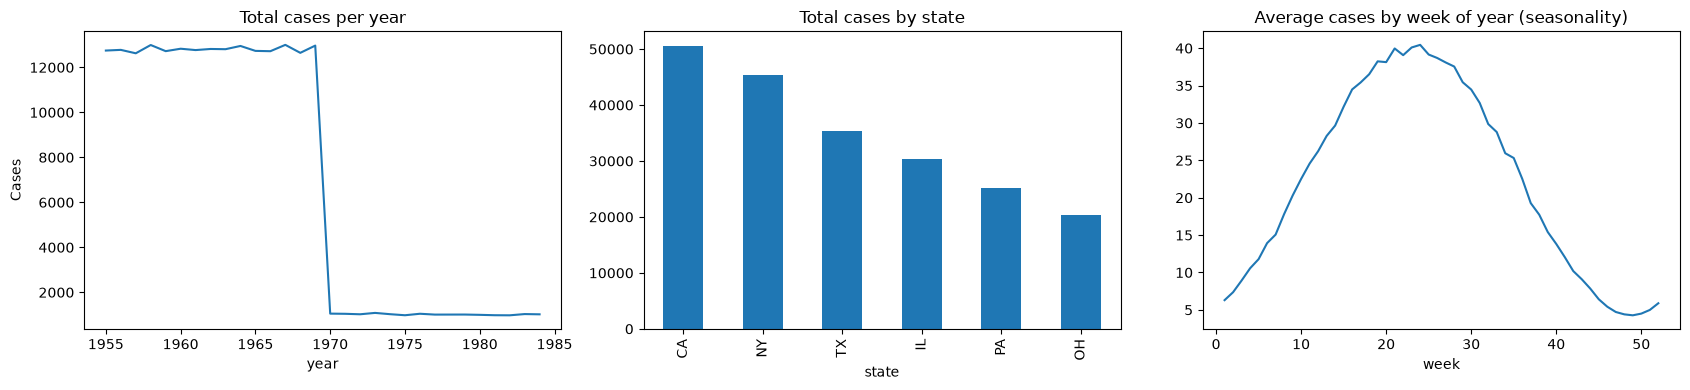

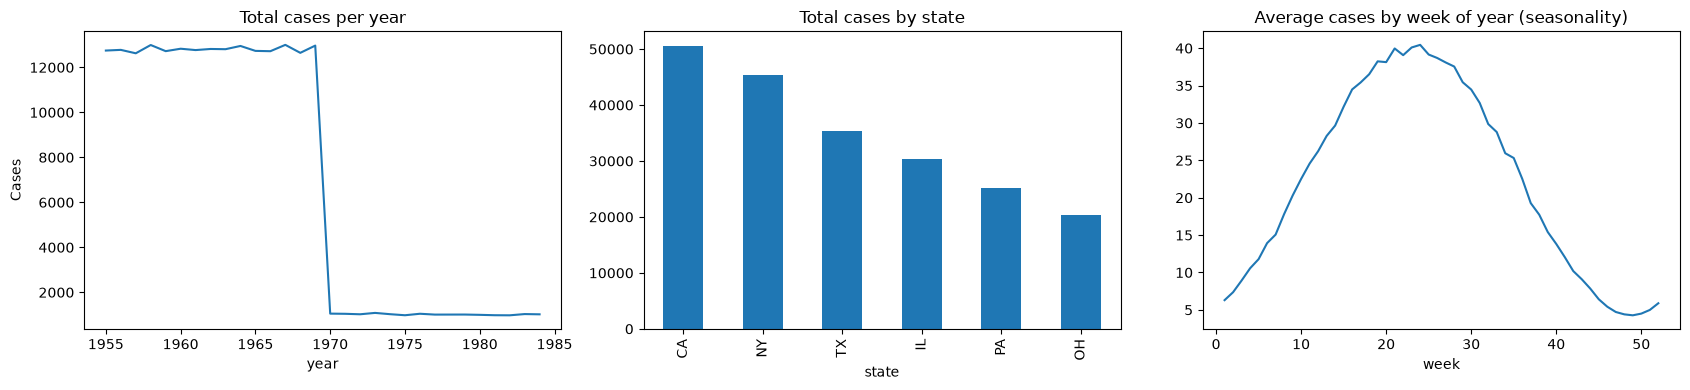

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

yearly.plot(ax=ax[0], title="Total cases per year")
ax[0].set_ylabel("Cases")

by_state.plot.bar(ax=ax[1], title="Total cases by state")

by_week.plot(
    ax=ax[2],
    title="Average cases by week of year (seasonality)"
)

plt.tight_layout()
plt.show()